# Cross-maze Comparison

`per_maze.ipynb` trains one model per maze session by session (every usable session of the maze, all mice, in calendar order): each session fine-tunes the model carried from the previous one on its first 60%, calibrates on the next 30% and is tested on its last 10%, and the first sessions are a warm-up that is never tested. Each maze has one bundle per seed (`analyses/artifacts/<MAZE>/ALL_MICE/seed_<k>/`), every seed a full run of the chain. Every number below is pooled over the test windows of all tested sessions, then reported as the mean across seeds with the sample standard deviation (sd) as its uncertainty. This notebook only reads the saved bundles (`metrics.json`, plus `arrays.npz` and `sigma_nets.pt` for sections 7 and 8; it never refits anything). Section 1 also reads one session from the database, and is skipped when the database is unreachable.

0. Setup: Imports And Loading The Maze Bundles
1. Data Example
2. Classification Task
3. Overall Conformal Performance By Maze
4. Calibration Performance On Test Data
5. Coverage-sharpness Trade-off
6. Class-conditional Conformal Performance
7. Decoder Error Correlations
8. Uncertainty Signals Contribution
9. Baseline, Ablation, And Pool-rule Sensitivity
10. Per-session Results Along The Chain

## 0. Setup: Imports And Loading The Maze Bundles

Imports the analysis dependencies, resolves the repository root, prepares the output directories for report and README figures, and loads every seed's chain bundle from `analyses/artifacts/`. The shared maze order, display labels, and plot colors are also defined here so the later tables and figures use the same naming and visual encoding.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# run from the repo root so `from src.X import ...` resolves whichever directory jupyter starts in
_cwd = Path.cwd()
REPO_ROOT = next(
    (p for p in (_cwd, *_cwd.parents) if (p / "pyproject.toml").exists()), _cwd
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.conformal.learned import signal_sensitivity_for_bundle
from src.utils.bundle_readers import (
    deployed_operating_point,
    error_correlations_for_bundle,
    load_maze_bundles,
    maze_summary_table,
    mean_sd,
    per_region_coverage_table,
    region_distribution,
    seed_method_table,
    seed_operating_curves,
    seed_per_session_table,
    seed_session_coverage,
    seed_values,
    whole_test_coverage,
)

REPORT_FIGURE_DIR = REPO_ROOT / "paper" / "figures"
README_IMAGE_DIR = REPO_ROOT / "docs" / "readme-images"
for _figure_dir in (REPORT_FIGURE_DIR, README_IMAGE_DIR):
    _figure_dir.mkdir(parents=True, exist_ok=True)


# save figs to be used in the paper (paper/figures/) and in the README.md (docs/readme-images/)
def save_report_figure(fig, filename):
    for figure_dir in (REPORT_FIGURE_DIR, README_IMAGE_DIR):
        fig.savefig(figure_dir / filename, dpi=300, bbox_inches="tight")


MAZE_ORDER = ("More_Water", "Y_Maze", "Nested_All")

# Display names for the plots only
MAZE_LABELS = {
    "More_Water": "Linear Maze",
    "Y_Maze": "Y Maze",
    "Nested_All": "Loop Maze",
}

# One fixed color per maze
MAZE_COLORS = {p: plt.cm.tab10(i) for i, p in enumerate(MAZE_ORDER)}

# load_maze_bundles reads every seed's bundle, mazes[paradigm] = {seed: bundle}, from
# analyses/artifacts/<Paradigm>/ALL_MICE/seed_<k>/
mazes, order = load_maze_bundles(
    REPO_ROOT / "analyses" / "artifacts", MAZE_ORDER, log_fn=print
)
for _p in order:
    print(f"{MAZE_LABELS.get(_p, _p)}: seeds {sorted(mazes[_p])}")


def fmt_mean_sd(mean, sd, digits=3, signed=False):
    """'mean +- sd' across seeds, or the mean alone when only one seed exists."""
    f = f"{{:{'+' if signed else ''}.{digits}f}}"
    if not np.isfinite(sd):
        return f.format(mean)
    return f"{f.format(mean)} ± {sd:.{digits}f}"


def err(sd):
    """An sd as an error-bar length. NaN (a single seed has no spread) draws no bar."""
    return np.asarray(sd, dtype=float)

Linear Maze: seeds [42]
Y Maze: seeds [42]
Loop Maze: seeds [42]


## 1. Data Example

Example neural input. The first 30 seconds of the first session in the first maze's bundle (the plot title names the mouse and date). The highlighted region corresponds to a 1 s interval input for the BC-VAE.

/tmp/ipykernel_196720/4149745553.py:39: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  span = ax.axvspan(


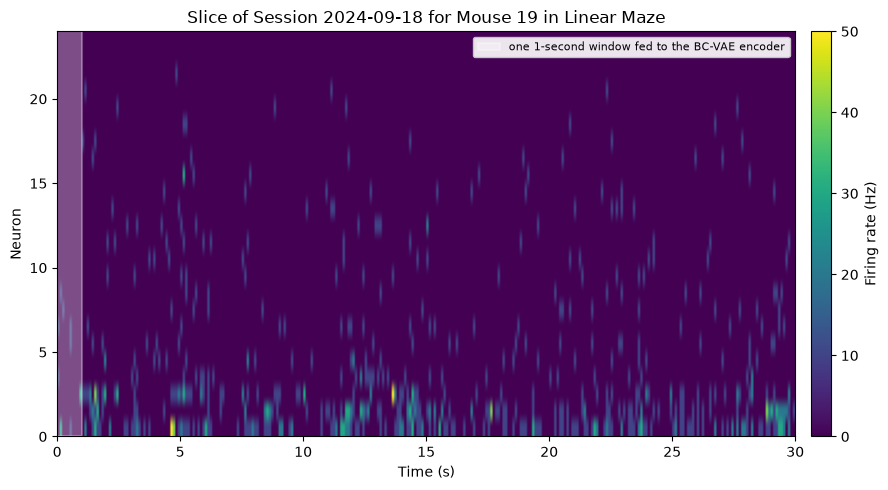

In [2]:
from src.data.config import BIN_WIDTH_SEC, WINDOW_SIZE
from src.data.hybrid_io import build_example_raster
from src.db.client import get_database
from src.db.database_utils import session_name_to_display

EXAMPLE_MAZE = order[0] if order else None  # which pooled maze to draw the example from
EXAMPLE_MAX_NEURONS = 40  # keep the plot readable
EXAMPLE_WINDOW_SEC = 30.0  # first N seconds of the trial shown

if EXAMPLE_MAZE:
    _runs = mazes[EXAMPLE_MAZE]
    session_name = _runs[min(_runs)]["sessions"][0]
    mouse_num, session_date = session_name_to_display(session_name)
    raster = None
    db_reached = False
    try:
        db = get_database()
        raster = build_example_raster(
            db,
            session_name,
            window_sec=EXAMPLE_WINDOW_SEC,
            max_neurons=EXAMPLE_MAX_NEURONS,
        )
        db_reached = True
    except Exception as exc:
        print(f"could not reach the database ({exc!r})")

    if raster:
        rates, n_shown = raster["rates"], raster["n_shown"]

        _tile_idx = (
            0  # which WINDOW_SIZE-bin (1s) window is highlighted as the encoder's input
        )
        fig, ax = plt.subplots(figsize=(9, 5))
        im = ax.imshow(
            rates,
            aspect="auto",
            origin="lower",
            cmap="viridis",
            extent=[0, EXAMPLE_WINDOW_SEC, 0, n_shown],
        )
        span = ax.axvspan(
            _tile_idx * WINDOW_SIZE * BIN_WIDTH_SEC,
            (_tile_idx + 1) * WINDOW_SIZE * BIN_WIDTH_SEC,
            color="white",
            alpha=0.3,
            lw=1.5,
            edgecolor="white",
            label="one 1-second window fed to the BC-VAE encoder",
        )
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Neuron")
        maze_label = MAZE_LABELS.get(EXAMPLE_MAZE, EXAMPLE_MAZE)
        ax.set_title(
            f"Slice of Session {session_date} for Mouse {mouse_num} in {maze_label}"
        )
        ax.legend(handles=[span], loc="upper right", fontsize=8, framealpha=0.9)
        fig.colorbar(im, ax=ax, label="Firing rate (Hz)", fraction=0.03, pad=0.02)

        plt.tight_layout()
        save_report_figure(fig, "encoder-input-example.png")
        plt.show()
    elif db_reached:
        print(f"no spike data found for {session_name}")

## 2. Classification Task

This schematic shows the 3 maze layouts with discrete region labels. The black dot marks the start of the trial.

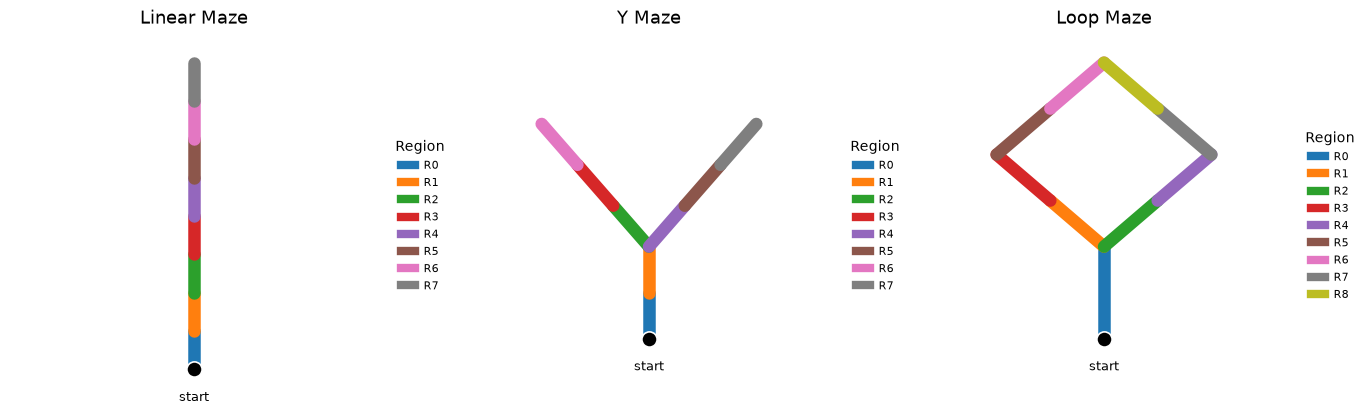

In [3]:
# Idealized, hand-built maze schematics. Branch topology and region order follow
# src.data.regions' classifiers
_START_COLOR = (
    "black"  # not one of tab10's colors, so it can't be mistaken for a region
)
_VIEW = (-6, 6)  # identical x/y range for every panel, so all three axes boxes match

MAZE_PATHS = {
    "More_Water": {  # vertical, bottom-to-top, like the other two mazes
        "start": (0, -5),
        "start_label_offset": (0, -16),
        "n_regions": 8,
        "paths": [{"points": [(0, -5), (0, 5)], "regions": list(range(8))}],
    },
    "Y_Maze": {
        "start": (0, -4),
        "start_label_offset": (0, -16),
        "n_regions": 8,
        "paths": [
            {"points": [(0, -4), (0, -1)], "regions": [0, 1]},
            {"points": [(0, -1), (-3.5, 3)], "regions": [2, 3, 6]},
            {"points": [(0, -1), (3.5, 3)], "regions": [4, 5, 7]},
        ],
    },
    "Nested_All": {
        "start": (0, -4),
        "start_label_offset": (0, -16),
        "n_regions": 9,
        "paths": [
            {"points": [(0, -4), (0, -1)], "regions": [0]},
            {"points": [(0, -1), (-3.5, 2), (0, 5)], "regions": [1, 3, 5, 6]},
            {"points": [(0, -1), (3.5, 2), (0, 5)], "regions": [2, 4, 7, 8]},
        ],
    },
}


def _region_color(r):
    return plt.cm.tab10(r % 10)


def _split_by_arclength(points, n):
    """n+1 points along a line, evenly spaced by arc length."""
    pts = np.array(points, dtype=float)
    seg_lens = np.linalg.norm(np.diff(pts, axis=0), axis=1)
    cum = np.concatenate([[0.0], np.cumsum(seg_lens)])
    out = []
    for t in np.linspace(0, cum[-1], n + 1):
        i = min(int(np.searchsorted(cum, t, side="right") - 1), len(seg_lens) - 1)
        frac = 0.0 if seg_lens[i] == 0 else (t - cum[i]) / seg_lens[i]
        out.append(pts[i] + frac * (pts[i + 1] - pts[i]))
    return out


if order:
    fig, axs = plt.subplots(
        1, len(order), figsize=(4.6 * len(order), 4.2), squeeze=False
    )
    for a, p in zip(axs[0], order, strict=True):
        shape = MAZE_PATHS[p]
        for path in shape["paths"]:
            regions = path["regions"]
            pts = _split_by_arclength(path["points"], len(regions))
            for (x0, y0), (x1, y1), r in zip(pts[:-1], pts[1:], regions, strict=True):
                a.plot(
                    [x0, x1],
                    [y0, y1],
                    color=_region_color(r),
                    lw=9,
                    solid_capstyle="round",
                    solid_joinstyle="round",
                )
        a.scatter(
            *shape["start"],
            color=_START_COLOR,
            s=120,
            zorder=5,
            edgecolor="white",
            linewidth=1.2,
        )
        a.annotate(
            "start",
            shape["start"],
            textcoords="offset points",
            xytext=shape["start_label_offset"],
            ha="center",
            va="top",
            fontsize=9,
        )
        a.set_title(MAZE_LABELS[p], fontsize=13)
        a.set_xlim(*_VIEW)
        a.set_ylim(*_VIEW)
        a.set_xticks([])
        a.set_yticks([])
        a.set_aspect("equal")
        for spine in a.spines.values():
            spine.set_visible(False)

        # labeled legend, built from the same _region_color() calls used
        # to draw the lines, so it can never show a color the maze itself doesn't use
        handles = [
            plt.Line2D([0], [0], color=_region_color(r), lw=6, label=f"R{r}")
            for r in range(shape["n_regions"])
        ]
        a.legend(
            handles=handles,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            fontsize=8,
            frameon=False,
            handlelength=1.2,
            title="Region",
        )

    plt.tight_layout()
    save_report_figure(fig, "maze-geometry.png")
    plt.show()

## 3. Overall Conformal Performance By Maze

Summary of decoder and conformal performance. $K$ is the total number of maze regions. Decoder accuracy is the proportion of test windows, pooled over every tested session, for which the decoder’s top probability predicted the true region; each session is tested with the model right after its own fine-tune. Coverage is the fraction of test windows for which the trust region contains the true maze region at the 90\% coverage target. The final column reports the mean trust region size normalized by $K$. Decoder accuracy, coverage, and trust region size are the mean ± sd across seeds.

In [4]:
rows = maze_summary_table(mazes, order)
if rows:
    maze_df = pd.DataFrame(
        {
            "Maze": [MAZE_LABELS[r["maze"]] for r in rows],
            "Seeds": [r["n_seeds"] for r in rows],
            "Mice": [r["n_mice"] for r in rows],
            "Sessions": [r["n_sessions"] for r in rows],
            "Maze Regions": [r["n_classes"] for r in rows],
            "Decoder Accuracy": [
                fmt_mean_sd(r["raw_test_acc"], r["raw_test_acc_sd"]) for r in rows
            ],
            "Coverage": [fmt_mean_sd(r["test_cov"], r["test_cov_sd"]) for r in rows],
            "|Ĉ|/K": [fmt_mean_sd(r["size_over_k"], r["size_over_k_sd"]) for r in rows],
        }
    ).set_index("Maze")
    display(maze_df)

,Seeds,Mice,Sessions,Maze Regions,Decoder Accuracy,Coverage,|Ĉ|/K
Maze,,,,,,,
Linear Maze,1,13,95,8,0.374,0.856,0.467
Y Maze,1,7,23,8,0.290,0.814,0.745
Loop Maze,1,2,14,9,0.270,0.865,0.712


## 4. Calibration Performance On Test Data

Calibration performance on test data. Left: Empirical test coverage per maze against the 90\% target, with the tested sessions as points displaying the spread per maze. Bars are the mean across seeds with ± 1 sd error bars; each point is one session's coverage averaged across seeds. Right: Achieved test coverage when the conformal scale is fine-tuned at every session for 19 coverage targets, 5\% to 95\% in 5\% steps; the star is the deployed model, which is the sweep's 90\% point; lines are the mean across seeds and bands ± 1 sd. The gap below the diagonal shows the empirical calibration cost between each session's calibration block and its later test block.

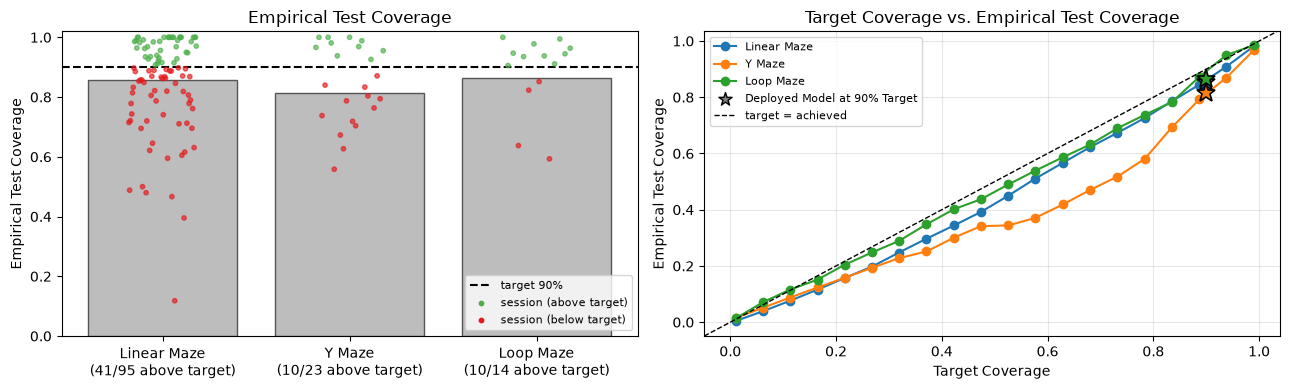

In [5]:
if mazes:
    _sc = {p: seed_session_coverage(mazes[p]) for p in order}
    _cov = {
        p: mean_sd(seed_values(mazes[p], lambda m: whole_test_coverage(m)["coverage"]))
        for p in order
    }
    _tgt = _sc[order[0]]["target"]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    _xlabels = [
        f"{MAZE_LABELS[p]}\n"
        f"({sum(_sc[p]['meets'])}/{len(_sc[p]['meets'])} above target)"
        for p in order
    ]
    ax[0].bar(
        _xlabels,
        [_cov[p][0][0] for p in order],
        yerr=[err(_cov[p][1])[0] for p in order],
        capsize=5,
        color="#bdbdbd",
        edgecolor="#555555",
    )
    for i, p in enumerate(order):
        vals = _sc[p]["coverage"]
        jitter = np.linspace(-0.18, 0.18, len(vals)) if vals else np.array([])
        cols = ["#4daf4a" if ok else "#e41a1c" for ok in _sc[p]["meets"]]
        ax[0].scatter(i + jitter, vals, c=cols, s=10, alpha=0.65, zorder=3)
    ax[0].axhline(_tgt, ls="--", color="k", lw=1.5, label=f"target {_tgt:.0%}")
    ax[0].scatter([], [], c="#4daf4a", s=10, label="session (above target)")
    ax[0].scatter([], [], c="#e41a1c", s=10, label="session (below target)")
    ax[0].set_ylabel("Empirical Test Coverage")
    ax[0].set_ylim(0, 1.02)
    ax[0].set_title("Empirical Test Coverage")
    ax[0].legend(fontsize=8, loc="lower right")
    # Retrained sweep (sigma refitted for each target), mean +- sd across seeds.
    for p in order:
        oc = seed_operating_curves(mazes[p])
        if oc["target"]:
            t, m = np.array(oc["target"]), np.array(oc["coverage"])
            sd = err(oc["coverage_sd"])
            ax[1].plot(t, m, "o-", color=MAZE_COLORS[p], label=MAZE_LABELS[p])
            ax[1].fill_between(t, m - sd, m + sd, color=MAZE_COLORS[p], alpha=0.2, lw=0)
    # the deployed model: the sweep's point at the deployed target
    for p in order:
        dep = seed_values(mazes[p], deployed_operating_point)
        c_m, c_sd = mean_sd([d["coverage"] for d in dep])
        ax[1].errorbar(
            _tgt,
            c_m[0],
            yerr=err(c_sd)[0],
            fmt="*",
            ms=14,
            mec="k",
            mew=1.2,
            color=MAZE_COLORS[p],
            ecolor="k",
            zorder=7,
        )
    ax[1].scatter(
        [],
        [],
        color="gray",
        s=100,
        marker="*",
        edgecolor="k",
        label=f"Deployed Model at {_tgt:.0%} Target",
    )
    ax[1].axline((0, 0), slope=1, ls="--", color="k", lw=1, label="target = achieved")
    ax[1].set_xlabel("Target Coverage")
    ax[1].set_ylabel("Empirical Test Coverage")
    ax[1].set_title("Target Coverage vs. Empirical Test Coverage")
    ax[1].legend(fontsize=8)
    ax[1].grid(alpha=0.3)
    plt.tight_layout()
    save_report_figure(fig, "coverage-drift-tax.png")
    plt.show()

## 5. Coverage-sharpness Trade-off

Coverage-sharpness trade-off. Achieved test coverage is shown on the horizontal axis, and mean trust region size normalized by total maze region count is shown on the vertical axis. Each curve fine-tunes the conformal scale at every session for 19 coverage targets, 5\% to 95\% in 5\% steps. The star marks the deployed 90\% target models reported in the Table from Section 3, which are the curves' 90\% points. Points are the mean across seeds, with ± 1 sd error bars on both axes.

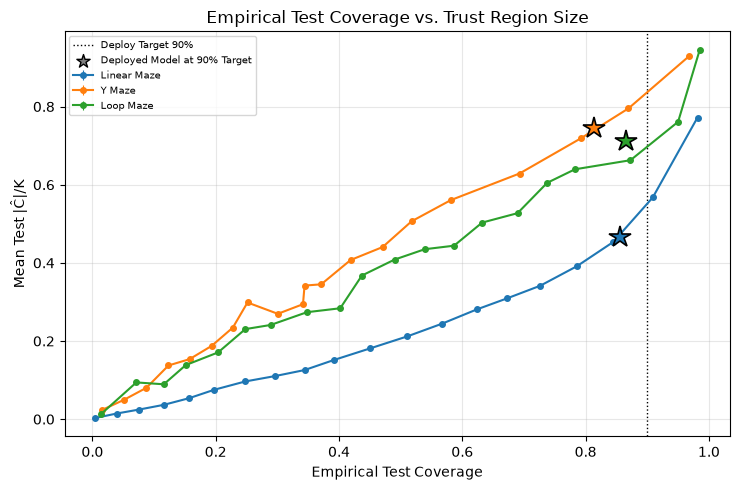

In [6]:
if mazes:
    fig, ax = plt.subplots(figsize=(7.5, 5))
    tgt = seed_operating_curves(mazes[order[0]])["coverage_target"]
    for p in order:
        col = MAZE_COLORS[p]
        oc = seed_operating_curves(mazes[p])
        if oc["coverage"]:
            ax.errorbar(
                oc["coverage"],
                oc["size_over_k"],
                xerr=err(oc["coverage_sd"]),
                yerr=err(oc["size_over_k_sd"]),
                fmt="o-",
                ms=4,
                elinewidth=0.8,
                color=col,
                label=MAZE_LABELS[p],
            )
        dep = seed_values(mazes[p], deployed_operating_point)
        c_m, c_sd = mean_sd([d["coverage"] for d in dep])
        s_m, s_sd = mean_sd([d["size_over_k"] for d in dep])
        if np.isfinite(c_m[0]) and np.isfinite(s_m[0]):
            ax.errorbar(
                c_m[0],
                s_m[0],
                xerr=err(c_sd)[0],
                yerr=err(s_sd)[0],
                fmt="*",
                ms=16,
                mec="k",
                mew=1.2,
                color=col,
                ecolor="k",
                zorder=7,
            )
    ax.axvline(tgt, ls=":", color="k", lw=1, label=f"Deploy Target {tgt:.0%}")
    ax.scatter(
        [],
        [],
        color="gray",
        s=100,
        marker="*",
        edgecolor="k",
        label=f"Deployed Model at {tgt:.0%} Target",
    )
    ax.set_xlabel("Empirical Test Coverage")
    ax.set_ylabel("Mean Test |Ĉ|/K")
    ax.set_title("Empirical Test Coverage vs. Trust Region Size")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    save_report_figure(fig, "coverage-sharpness-frontier.png")
    plt.show()

## 6. Class-conditional Conformal Performance

Conformal performance per region and label distribution. Each subplot corresponds to one maze. For inputs whose true label is the corresponding maze region, red bars show empirical test coverage, and green bars show the mean trust region size normalized by the number of maze regions. Blue bars show the region's share of data points for the entire dataset. The dashed line marks the 90\% coverage target. Bars are the mean across seeds, with ± 1 sd error bars. A region with no test data points has no test coverage or trust region size estimate and shows as a gap.

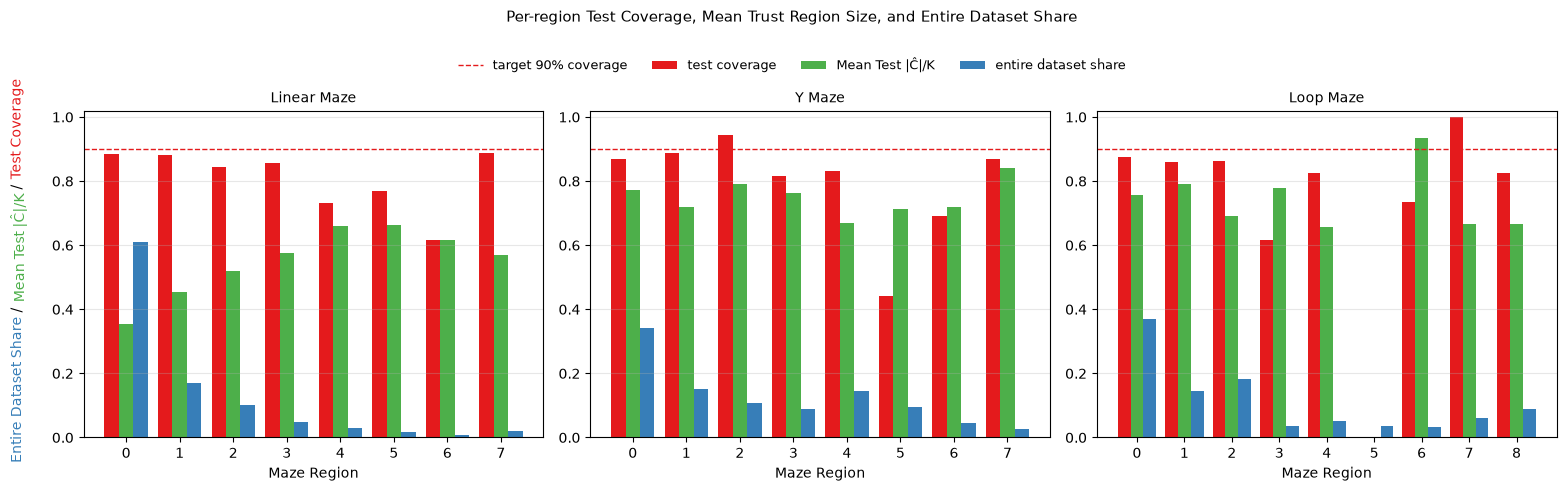

In [7]:
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, VPacker

if mazes:

    def _colored_ylabel(ax, segments, fontsize=10):
        """Stack (text, color) segments into one rotated y-axis label, read
        bottom-to-top, each segment colored like the bar series it names."""
        boxes = [
            TextArea(
                text,
                textprops=dict(
                    color=color, size=fontsize, rotation=90, ha="left", va="bottom"
                ),
            )
            for text, color in segments
        ]
        box = VPacker(children=boxes, align="bottom", pad=0, sep=0)
        anchored = AnchoredOffsetbox(
            loc="center left",
            child=box,
            pad=0.0,
            frameon=False,
            bbox_to_anchor=(-0.16, 0.5),
            bbox_transform=ax.transAxes,
            borderpad=0.0,
        )
        ax.add_artist(anchored)

    fig, axs = plt.subplots(
        1, len(order), figsize=(5.2 * len(order), 4.5), squeeze=False
    )
    for col, p in enumerate(order):
        a = axs[0][col]
        ts = seed_values(mazes[p], per_region_coverage_table)
        t = ts[0]
        assert all(x["regions"] == t["regions"] for x in ts), "regions differ by seed"
        r = np.arange(len(t["regions"]))
        rd = region_distribution(mazes[p][min(mazes[p])])
        cov_m, cov_sd = mean_sd([x["learned"] for x in ts])
        size_m, size_sd = mean_sd([x["size_over_k"] for x in ts])
        a.bar(
            r - 0.27,
            cov_m,
            0.27,
            yerr=err(cov_sd),
            capsize=2,
            color="#e41a1c",
            label="test coverage",
        )
        a.bar(
            r,
            size_m,
            0.27,
            yerr=err(size_sd),
            capsize=2,
            color="#4daf4a",
            label="Mean Test |Ĉ|/K",
        )
        a.bar(
            r + 0.27,
            rd["fraction"],
            0.27,
            color="#377eb8",
            label="entire dataset share",
        )
        a.axhline(
            t["target"],
            ls="--",
            color="#e41a1c",
            lw=1,
            label=f"target {t['target']:.0%} coverage",
        )
        a.set_xticks(r)
        a.set_xticklabels(t["regions"])
        a.set_ylim(0, 1.02)
        a.set_title(MAZE_LABELS[p], fontsize=10)
        a.set_xlabel("Maze Region")
        a.grid(alpha=0.3, axis="y")

    _colored_ylabel(
        axs[0][0],
        [
            ("Test Coverage", "#e41a1c"),
            (" / ", "black"),
            ("Mean Test |Ĉ|/K", "#4daf4a"),
            (" / ", "black"),
            ("Entire Dataset Share", "#377eb8"),
        ],
    )
    # one shared legend for all 3 panels instead of a repeated in-axes legend per panel
    handles, labels = axs[0][0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=4,
        bbox_to_anchor=(0.5, 1.0),
        fontsize=9,
        frameon=False,
    )
    fig.suptitle(
        "Per-region Test Coverage, Mean Trust Region Size, and Entire Dataset Share",
        fontsize=11,
        y=1.08,
    )
    plt.tight_layout()
    save_report_figure(fig, "per-region-coverage.png")
    plt.show()

## 7. Decoder Error Correlations

Decoder error Pearson correlations over grouped test data points. Decoder error is 0 or 1 per data point, so data points are grouped and each group contributes its mean value and its error rate. The first correlation groups by normalized trust region size $|\widehat{\mathcal{C}}|/K$, one group per size level. The second groups by the MLP uncertainty scale $\sigma_\theta(x)$, in 10 equal-count bins; every session has its own $\sigma_\theta$, whose overall level carries no meaning, so each window's $\sigma_\theta(x)$ is taken relative to its session's median. Each group is weighted by its number of data points. The table reports the mean ± sd across seeds and each seed's value. Positive values indicate that decoder errors tend to coincide with larger trust regions or larger MLP scales.

In [8]:
rows = []
for p in order:
    cs = seed_values(mazes[p], error_correlations_for_bundle)
    if not cs:
        continue
    row = {"maze": MAZE_LABELS[p], "seeds": len(cs)}
    for key, label in (
        ("corr_error_size", "Pearson correlation(error, size)"),
        ("corr_error_sigma", "Pearson correlation(error, sigma)"),
    ):
        vals = [c[key] for c in cs]
        m, sd = mean_sd(vals)
        row[label] = fmt_mean_sd(m[0], sd[0], digits=2, signed=True)
        row[f"{label}, per seed"] = "  ".join(f"{v:+.2f}" for v in vals)
    rows.append(row)

corr_df = pd.DataFrame(rows).set_index("maze") if rows else pd.DataFrame()
if len(corr_df):
    display(corr_df)

,seeds,"Pearson correlation(error, size)","Pearson correlation(error, size), per seed","Pearson correlation(error, sigma)","Pearson correlation(error, sigma), per seed"
maze,,,,,
Linear Maze,1,+0.86,+0.86,+0.99,+0.99
Y Maze,1,+0.61,+0.61,+0.68,+0.68
Loop Maze,1,-0.78,-0.78,-0.86,-0.86


## 8. Uncertainty Signals Contribution

Sensitivity of the learned conformal scale to each uncertainty signal. Bars show the mean relative change of $\sigma_\theta(x)$, $|\partial \log \sigma_\theta(x) / \partial z|$, per standard deviation $z$ of each input uncertainty signal, computed with each session's $\sigma_\theta$ on that session's test windows and averaged over all test windows of each maze. Bars are the mean across seeds with ± 1 sd error bars; the dots are the individual seeds. The relative change does not depend on the overall level of $\sigma_\theta(x)$, so the mazes can be compared directly.

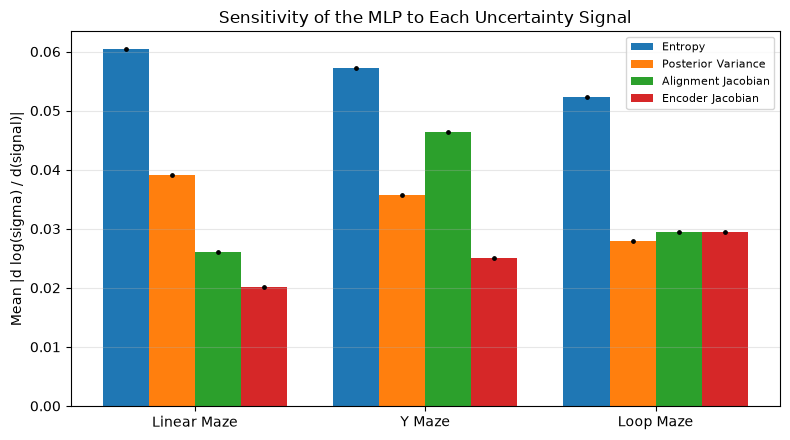

In [9]:
if mazes:
    _sig_labels = {
        "entropy": "Entropy",
        "variance": "Posterior Variance",
        "align_jacobian": "Alignment Jacobian",
        "enc_jacobian": "Encoder Jacobian",
    }
    _sens = {}  # paradigm -> list over seeds of signal_sensitivity_for_bundle results
    for p in order:
        s = seed_values(mazes[p], signal_sensitivity_for_bundle)
        if s:
            _sens[p] = s

    if _sens:
        _signal_names = next(iter(_sens.values()))[0]["signals"]
        fig, ax = plt.subplots(figsize=(8, 4.5))
        _x = np.arange(len(order))
        _w = 0.8 / len(_signal_names)
        for j, s in enumerate(_signal_names):
            _xj = _x + (j - (len(_signal_names) - 1) / 2) * _w
            per_seed = [
                [x["mean_abs_log_grad"][j] for x in _sens[p]] if p in _sens else []
                for p in order
            ]
            stats = [mean_sd(v) if v else (np.array([np.nan]),) * 2 for v in per_seed]
            ax.bar(
                _xj,
                [m[0] for m, _ in stats],
                _w,
                yerr=[err(sd)[0] for _, sd in stats],
                capsize=3,
                label=_sig_labels.get(s, s),
            )
            for xi, v in zip(_xj, per_seed, strict=True):  # one dot per seed
                ax.scatter([xi] * len(v), v, s=6, color="k", zorder=3)
        ax.set_xticks(_x)
        ax.set_xticklabels([MAZE_LABELS[p] for p in order])
        ax.set_ylabel("Mean |d log(sigma) / d(signal)|")
        ax.set_title("Sensitivity of the MLP to Each Uncertainty Signal")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3, axis="y")
        plt.tight_layout()
        save_report_figure(fig, "signal-confound.png")
        plt.show()

## 9. Baseline, Ablation, And Pool-rule Sensitivity

The method against a fresh model trained on each session alone with standard split conformal ($\sigma = 1$, one threshold for every region), and against the same chain with $\sigma = 1$ (class-conditional, same calibration), which isolates what the learned scale adds. Mean |gap| is the mean over sessions of $|\text{coverage} - 0.90|$. The second table splits the tested sessions into returning mice and each mouse's first session. The third table varies how many past sessions a region with too few calibration windows may borrow from (B1, B3, B5; B3 is the method). All values are pooled over test windows, mean ± sd across seeds.

In [ ]:
METHOD_LABELS = {
    "chain_B3": "Chain, learned σ",
    "chain_sigma1": "Chain, σ = 1",
    "fresh": "Fresh model, standard conformal",
}
_fields = ("coverage", "size_over_k", "accuracy", "mean_abs_gap")
_names = {
    "coverage": "Coverage",
    "size_over_k": "|Ĉ|/K",
    "accuracy": "Accuracy",
    "mean_abs_gap": "Mean |gap|",
    "share_global": "Global fallback",
}


def method_rows(group, methods, fields=_fields, labels=METHOD_LABELS):
    """One row per (maze, method): mean ± sd across seeds of each field."""
    rows = []
    for p in order:
        t = seed_method_table(mazes[p], group, fields)
        for m in methods:
            if m in t:
                rows.append(
                    {"Maze": MAZE_LABELS[p], "Method": labels.get(m, m)}
                    | {_names[f]: fmt_mean_sd(*t[m][f]) for f in fields}
                )
    return pd.DataFrame(rows).set_index(["Maze", "Method"]) if rows else pd.DataFrame()


if mazes:
    display(method_rows("all", ["chain_B3", "chain_sigma1", "fresh"]))
    for group, title in (
        ("returning", "returning mice"),
        ("first", "first session of a mouse"),
    ):
        _t = method_rows(group, ["chain_B3", "fresh"])
        print(f"\n{title}")
        if len(_t):
            display(_t)
        else:
            print("  no tested sessions (all in the warm-up)")
    print("\npool-rule sensitivity")
    display(
        method_rows(
            "all",
            ["chain_B1", "chain_B3", "chain_B5"],
            ("coverage", "size_over_k", "mean_abs_gap", "share_global"),
            {"chain_B1": "B1", "chain_B3": "B3 (method)", "chain_B5": "B5"},
        )
    )

## 10. Per-session Results Along The Chain

Coverage and decoder accuracy of every tested session, in chain order (calendar order across mice). Lines are the mean across seeds and bands ± 1 sd; grey vertical lines mark a mouse's first session. The chain accumulates experience and neuron counts change along it, so position along the chain is not a drift axis; the figure is descriptive.

In [ ]:
if mazes:
    fig, axs = plt.subplots(
        len(order), 1, figsize=(11, 2.8 * len(order)), squeeze=False
    )
    for a, p in zip(axs[:, 0], order, strict=True):
        t = seed_per_session_table(mazes[p])
        x = np.arange(len(t["sessions"]))
        for key, color, label in (
            ("coverage", MAZE_COLORS[p], "coverage"),
            ("accuracy", "0.35", "decoder accuracy"),
        ):
            m, sd = np.array(t[key]), err(t[f"{key}_sd"])
            a.plot(x, m, "o-", ms=3, color=color, label=label)
            a.fill_between(x, m - sd, m + sd, color=color, alpha=0.2, lw=0)
        for i, first in enumerate(t["first_of_mouse"]):
            if first:
                a.axvline(i, color="0.85", lw=1, zorder=0)
        a.axhline(t["target"], ls="--", color="k", lw=1)
        a.set_ylim(0, 1.02)
        a.set_title(MAZE_LABELS[p], fontsize=10)
        a.set_ylabel("per session")
        a.grid(alpha=0.3)
    axs[0, 0].legend(fontsize=8, loc="lower right")
    axs[-1, 0].set_xlabel("tested session, chain order")
    plt.tight_layout()
    save_report_figure(fig, "chain-per-session.png")
    plt.show()